# Разные методы генерации из диффузионных моделей — Этап 1

## 0. Окружение


In [1]:
import io
import json
import os
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

import diffusers
from diffusers import DDIMScheduler, DDPMPipeline

# %config InlineBackend.figure_format = 'retina'

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
MODEL_ID = "google/ddpm-cifar10-32"

print("python:", sys.version.split()[0])
print("torch:", torch.__version__, "| diffusers:", diffusers.__version__)
print("device:", DEVICE)

# --- наличие подготовленных данных (см. prepare_data.py) ---------------------
need = [
    "data/fixed_noise.pt",
    "data/fid_stats_cifar10_test.npz",
]
missing = [p for p in need if not os.path.exists(p)]
if not os.path.exists("data/cifar10_test/00000.png"):
    missing.append("data/cifar10_test/*.png")
if missing:
    # На этой машине у torch.hub/python-urllib проблемы с SSL-сертификатами,
    # поэтому веса Inception для FID скачаны заранее через curl в
    # ~/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
    raise FileNotFoundError(f"Нет данных: {missing}. Запустите `python prepare_data.py`")
print("данные на месте:", need)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1102 01:12:48.605000 192 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


python: 3.12.10
torch: 2.12.0 | diffusers: 0.42.1
device: mps
данные на месте: ['data/fixed_noise.pt', 'data/fid_stats_cifar10_test.npz']


## 1. Модель


In [2]:
pipe = DDPMPipeline.from_pretrained(MODEL_ID)
unet = pipe.unet.to(DEVICE).eval()
BASE_CFG = dict(pipe.scheduler.config)  # конфиг сScheduler'а из чекпойнта

n_params = sum(p.numel() for p in unet.parameters())
print(f"{type(unet).__name__}: {n_params/1e6:.1f}M параметров")
print("config:", {k: BASE_CFG[k] for k in
      ["num_train_timesteps", "beta_start", "beta_end", "beta_schedule",
       "prediction_type", "clip_sample", "timestep_spacing"]})

# Табличные величины расписания (ᾱ_t) берём из шедулера Diffusers — так мы
# гарантированно используем ровно те же alphas_cumprod, что и референсные сэмплеры.
_sched = DDIMScheduler.from_config(BASE_CFG)
ACPROD = _sched.alphas_cumprod.to(DEVICE)      # ᾱ_t, t = 0..999
print("ᾱ_0 =", float(ACPROD[0]), "| ᾱ_999 =", float(ACPROD[-1]))

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

Loading pipeline components...: 100%|██████████| 2/2 [00:00<00:00, 36.91it/s]

UNet2DModel: 35.7M параметров
config: {'num_train_timesteps': 1000, 'beta_start': 0.0001, 'beta_end': 0.02, 'beta_schedule': 'linear', 'prediction_type': 'epsilon', 'clip_sample': True, 'timestep_spacing': 'leading'}
ᾱ_0 = 0.9998999834060669 | ᾱ_999 = 4.035830352222547e-05


### 1.1 Класс-обвязка `EpsilonNet`


In [3]:
class EpsilonNet:
    '''Обвязка ε-модели google/ddpm-cifar10-32 под сэмплеры любых параметризаций.

    Хранит табличное VP-расписание (ᾱ_t) из чекпойнта и умеет:
      * eps(x_t, t)        — «сырой» вызов модели (для DDIM);
      * x0_from_eps(...)   — прогноз чистого изображения (для DPM-Solver++);
      * D(x, sigma)        — EDM-денойзер (для Heun), смена переменных VP -> EDM
      * t_of_sigma(sigma)  — обратный переход EDM σ -> ближайший train-timestep.
    '''

    def __init__(self, unet, alphas_cumprod, device):
        self.unet = unet
        self.device = device
        self.acp = alphas_cumprod                      # ᾱ_t
        self.alpha = alphas_cumprod.sqrt()             # α_t
        self.sigma_vp = (1 - alphas_cumprod).sqrt()    # σ_t (VP)
        self.lam = torch.log(self.alpha) - torch.log(self.sigma_vp)  # λ_t
        self.sigma_edm = self.sigma_vp / self.alpha    # EDM σ_t (возрастает по t)

    # ------------------------------------------------------------------ базовые
    @torch.no_grad()
    def eps(self, x, t):
        t = torch.as_tensor(t, device=self.device, dtype=torch.long).reshape(-1)
        return self.unet(x, t).sample

    def x0_from_eps(self, x, t, eps):
        a, s = self.alpha[t], self.sigma_vp[t]
        return (x - s * eps) / a

    # ------------------------------------------------------------------ EDM-вид
    def t_of_sigma(self, sigma):
        '''Ближайший train-timestep к данному EDM σ (по log σ).'''
        sig = torch.as_tensor(sigma, device=self.device, dtype=torch.float32).reshape(-1)
        idx = (self.sigma_edm.log()[None, :] - sig.log()[:, None]).abs().argmin(dim=1)
        return idx

    @torch.no_grad()
    def D(self, x, sigma):
        '''EDM-денойзер: D(x;σ) = x − σ·ε̂(α_{t(σ)}·x, t(σ)),  x в EDM-параметризации.'''
        t = self.t_of_sigma(sigma)
        a = self.alpha[t].view(-1, 1, 1, 1)
        x_vp = a * x
        eps = self.unet(x_vp, t).sample
        sig = torch.as_tensor(sigma, device=self.device, dtype=torch.float32).view(-1, 1, 1, 1)
        return x - sig * eps


MODEL = EpsilonNet(unet, ACPROD, DEVICE)
print("обвязка готова:", MODEL.__class__.__name__)

обвязка готова: EpsilonNet


### 1.2 Проверка обвязки


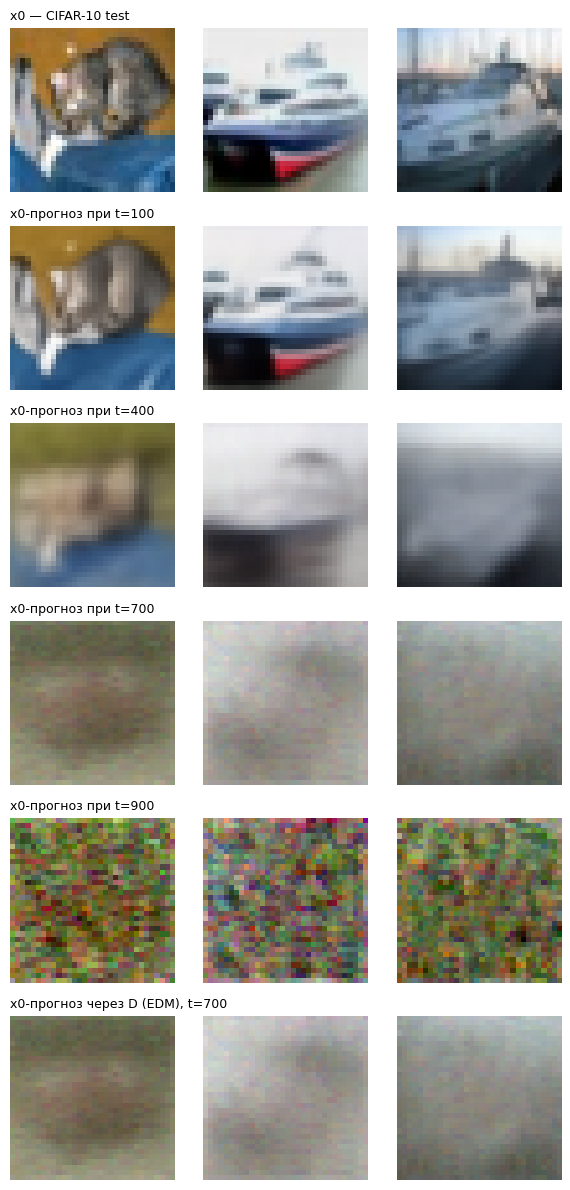

In [4]:
# --- качественная проверка обвязки -------------------------------------------
# Реальные изображения CIFAR-10 test зашумляем на нескольких уровнях t и
# восстанавливаем x̂0 через обвязку. Ожидание: при малом t восстановление почти
# точное, с ростом t детали теряются и прогноз уходит к «типичным» образам.
# Последняя строка — то же через EDM-денойзер D: картинка совпадает с t=700.
from PIL import Image

ids = [0, 1, 2]
x0 = np.stack([np.array(Image.open(f"data/cifar10_test/{i:05d}.png"), dtype=np.float32)
               for i in ids]).transpose(0, 3, 1, 2) / 127.5 - 1.0     # диапазон [-1, 1]
x0 = torch.from_numpy(x0).to(DEVICE)

g = torch.Generator(device="cpu").manual_seed(7)
eps = torch.randn(tuple(x0.shape), generator=g).to(DEVICE)

T_SHOW = [100, 400, 700, 900]
noisy = {t: MODEL.alpha[t] * x0 + MODEL.sigma_vp[t] * eps for t in T_SHOW}

rows = [("x0 — CIFAR-10 test", x0)]
for t in T_SHOW:
    x0h = MODEL.x0_from_eps(noisy[t], t, MODEL.eps(noisy[t], t)).clamp(-1, 1)
    rows.append((f"x0-прогноз при t={t}", x0h))
x_edm = noisy[700] / MODEL.alpha[700]
rows.append(("x0-прогноз через D (EDM), t=700",
             MODEL.D(x_edm, MODEL.sigma_edm[700]).clamp(-1, 1)))

fig, axes = plt.subplots(len(rows), 3, figsize=(3 * 2.0, len(rows) * 2.0))
for r, (title, img) in enumerate(rows):
    for c in range(3):
        axes[r, c].imshow(((img[c].cpu().numpy().transpose(1, 2, 0) + 1) / 2).clip(0, 1))
        axes[r, c].set_axis_off()
    axes[r, 0].set_title(title, loc="left", fontsize=9)
plt.tight_layout()
plt.show()


## 2. Данные и фиксированные шумы


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4402096..2.3944669].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3866391..2.206107].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1547655..2.1222248].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5805101..2.1169662].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1533009..2.620118].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5247188..2.1856751].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2084886..2.4261289].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4297285..2.55986].


фиксированные шумы: (1000, 3, 32, 32) | seed: 2026 | mean 0.001 std 1.000
FID-статистики CIFAR-10 test: (2048,) (2048, 2048)


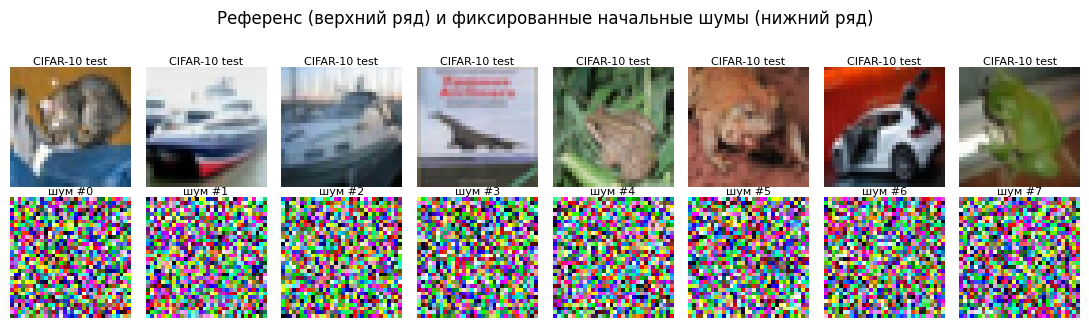

In [5]:
noise_d = torch.load("data/fixed_noise.pt")
FIXED_NOISE = noise_d["noise"]
print("фиксированные шумы:", tuple(FIXED_NOISE.shape),
      "| seed:", noise_d["seed"],
      "| mean %.3f std %.3f" % (FIXED_NOISE.mean(), FIXED_NOISE.std()))

ref_stats = np.load("data/fid_stats_cifar10_test.npz")
MU_REF, SIGMA_REF = ref_stats["mu"], ref_stats["sigma"]
print("FID-статистики CIFAR-10 test:", MU_REF.shape, SIGMA_REF.shape)

# --- примеры реальных изображений и фиксированных шумов -----------------------
real_files = sorted(os.listdir("data/cifar10_test"))[:16]
real = np.stack([np.asarray(Image.open(f"data/cifar10_test/{f}")) for f in real_files])

fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
for j in range(8):
    axes[0, j].imshow(real[j]); axes[0, j].set_title("CIFAR-10 test", fontsize=8, pad=2)
    axes[1, j].imshow((FIXED_NOISE[j].permute(1, 2, 0).numpy() + 1) / 2)
    axes[1, j].set_title(f"шум #{j}", fontsize=8, pad=2)
for ax in axes.ravel():
    ax.set_axis_off()
fig.suptitle("Референс (верхний ряд) и фиксированные начальные шумы (нижний ряд)", y=1.02)
plt.tight_layout(); plt.show()

## 3. Baseline: DDIM из Diffusers


In [6]:
def generate_ddim(noise, n_steps, batch_size=250, eta=0.0):
    '''Генерация DDIM из Diffusers на фиксированных шумах.

    Returns: (изображения [-1,1] на CPU, суммарное число вызовов модели, время, сек)
    '''
    sched = DDIMScheduler.from_config(BASE_CFG)
    sched.set_timesteps(n_steps)
    ts = sched.timesteps.tolist()
    images, model_calls, t0 = [], 0, time.perf_counter()
    with torch.no_grad():
        for i in range(0, len(noise), batch_size):
            x = noise[i:i + batch_size].to(DEVICE)
            for t in ts:
                eps = unet(x, t).sample
                model_calls += 1
                x = sched.step(eps, t, x, eta=eta).prev_sample
            images.append(x.float().cpu())
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    return torch.cat(images), model_calls, time.perf_counter() - t0


# ---------------------------------------------------------------- FID-инструменты
from pytorch_fid.fid_score import calculate_frechet_distance
from pytorch_fid.inception import InceptionV3

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()


@torch.no_grad()
def _activations(imgs_uint8):
    '''imgs_uint8: (N,3,32,32) uint8 -> активации InceptionV3 (2048-d).'''
    x = imgs_uint8.to(DEVICE).float() / 255.0
    acts = []
    for i in range(0, len(x), 200):
        a = inception(x[i:i + 200])[0].squeeze(-1).squeeze(-1)
        acts.append(a.float().cpu().numpy())
    return np.concatenate(acts)


def fid_from_uint8(imgs_uint8):
    a = _activations(imgs_uint8)
    mu, sigma = a.mean(axis=0), np.cov(a, rowvar=False)
    return calculate_frechet_distance(mu, sigma, MU_REF, SIGMA_REF)


def to_uint8(imgs):
    '''[-1,1] float -> uint8 (тот же путь, что и сохранение в PNG).'''
    return ((imgs.clamp(-1, 1) + 1) / 2 * 255).round().to(torch.uint8)

In [7]:
# --- sanity-check FID-конвейера ------------------------------------------------
# Статистики 10k CIFAR-10 test, посчитанные через тензорный путь (как для генераций),
# должны совпасть с эталонными из файла => FID(test, test) ≈ 0.
files = sorted(os.listdir("data/cifar10_test"))
test_uint8 = torch.stack([
    torch.from_numpy(np.asarray(Image.open(f"data/cifar10_test/{f}"))).permute(2, 0, 1)
    for f in files
])
print("CIFAR-10 test:", tuple(test_uint8.shape), test_uint8.dtype)
t0 = time.perf_counter()
fid_sanity = fid_from_uint8(test_uint8)
print(f"FID(CIFAR-10 test, CIFAR-10 test) = {fid_sanity:.4f}  ({time.perf_counter()-t0:.0f}s на 10k)")
assert fid_sanity < 0.1, "FID-конвейер рассинхронизирован с эталонными статистиками!"
print("=> FID-конвейер валиден")

/var/folders/99/gnf4jtyx15vb5nk9t8_b0jt40000gp/T/ipykernel_192/1883640873.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  torch.from_numpy(np.asarray(Image.open(f"data/cifar10_test/{f}"))).permute(2, 0, 1)


CIFAR-10 test: (10000, 3, 32, 32) torch.uint8


FID(CIFAR-10 test, CIFAR-10 test) = 0.0000  (45s на 10k)
=> FID-конвейер валиден


In [8]:
# --- прогрев MPS (не замеряется) ----------------------------------------------
_ = generate_ddim(FIXED_NOISE[:8], n_steps=10, batch_size=8)

# --- baseline: DDIM, 50 шагов, 1000 фиксированных шумов ------------------------
imgs50, model_calls, t50 = generate_ddim(FIXED_NOISE, n_steps=50)
fid50 = fid_from_uint8(to_uint8(imgs50))

BASELINE = dict(method="DDIM (Diffusers)", steps_per_image=50, n_model_calls=model_calls,
                n_images=len(imgs50), time_s=t50, fid=fid50)
print(json.dumps(BASELINE, indent=2))
print(f"время на 1000 изображений: {t50:.1f}s | на одно: {t50/len(imgs50)*1000:.0f}ms "
      f"| на один вызов модели (батч 250): {t50/model_calls:.3f}s")

{
  "method": "DDIM (Diffusers)",
  "steps_per_image": 50,
  "n_model_calls": 200,
  "n_images": 1000,
  "time_s": 235.2767635829805,
  "fid": 43.16794279180516
}
время на 1000 изображений: 235.3s | на одно: 235ms | на один вызов модели (батч 250): 1.176s


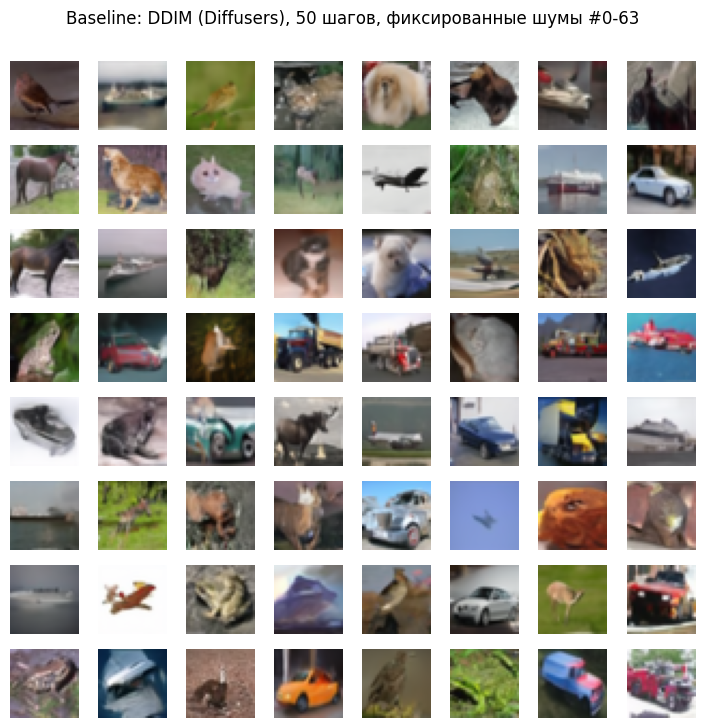

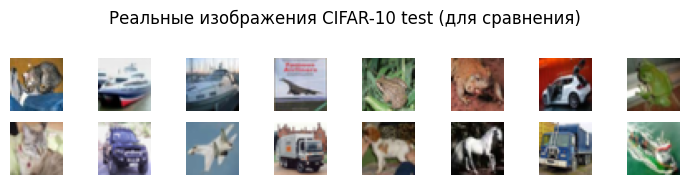

In [9]:
def show_grid(imgs, n_rows, n_cols, title, scale=1.0):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9 * scale, n_rows * 0.9 * scale))
    for k, ax in enumerate(np.asarray(axes).ravel()):
        ax.imshow((imgs[k].clamp(-1, 1).permute(1, 2, 0).numpy() + 1) / 2)
        ax.set_axis_off()
    fig.suptitle(title, y=1.005)
    plt.tight_layout(); plt.show()


# --- визуальная проверка baseline ----------------------------------------------
show_grid(imgs50[:64], 8, 8, "Baseline: DDIM (Diffusers), 50 шагов, фиксированные шумы #0-63")

# --- рядом с реальными для сравнения качества ----------------------------------
show_grid(torch.from_numpy(real[:16]).permute(0, 3, 1, 2).float() / 255 * 2 - 1,
          2, 8, "Реальные изображения CIFAR-10 test (для сравнения)")

### 3.1 Качество vs число шагов


In [10]:
STEPS_GRID = [10, 20, 50, 100]
results = {}

os.makedirs("data/generated", exist_ok=True)
for n in STEPS_GRID:
    if n == 50:
        imgs, calls, t = imgs50, model_calls, t50          # переиспользуем baseline-прогон
    else:
        imgs, calls, t = generate_ddim(FIXED_NOISE, n_steps=n)
    torch.save(to_uint8(imgs), f"data/generated/ddim_{n}steps.pt")
    results[n] = dict(steps_per_image=n, n_model_calls=calls, time_s=t,
                      fid=fid_from_uint8(to_uint8(imgs)))
    print(f"шагов={n:>3}: FID={results[n]['fid']:.2f}  time={t:.1f}s")

# --- MSE к детерминированной генерации с 100 шагами (тот же шум) ----------------
ref100 = torch.load("data/generated/ddim_100steps.pt").float() / 255
for n in STEPS_GRID:
    imgs_n = torch.load(f"data/generated/ddim_{n}steps.pt").float() / 255
    if n == 100:
        results[n]["mse_vs_100steps"] = 0.0
        continue
    mse = ((imgs_n - ref100) ** 2).mean().item()
    results[n]["mse_vs_100steps"] = mse
    results[n]["psnr_vs_100steps"] = -10 * np.log10(mse)

df = pd.DataFrame(results).T
df.index.name = "число шагов"
df[["fid", "time_s", "mse_vs_100steps", "psnr_vs_100steps"]] = \
    df[["fid", "time_s", "mse_vs_100steps", "psnr_vs_100steps"]].round(3)
display(df)

with open("data/results_stage1.json", "w") as f:
    json.dump({"baseline": BASELINE, "ddim_sweep": {str(k): v for k, v in results.items()}}, f, indent=2)
print("метрики сохранены в data/results_stage1.json")

шагов= 10: FID=59.65  time=52.8s


шагов= 20: FID=48.84  time=104.0s


шагов= 50: FID=43.17  time=235.3s


шагов=100: FID=40.82  time=490.3s


,steps_per_image,n_model_calls,time_s,fid,mse_vs_100steps,psnr_vs_100steps
число шагов,,,,,,
10,10.0,40.0,52.839,59.653,0.003,24.717
20,20.0,80.0,103.993,48.835,0.001,28.353
50,50.0,200.0,235.277,43.168,0.000,33.483
100,100.0,400.0,490.273,40.820,0.000,NaN


метрики сохранены в data/results_stage1.json


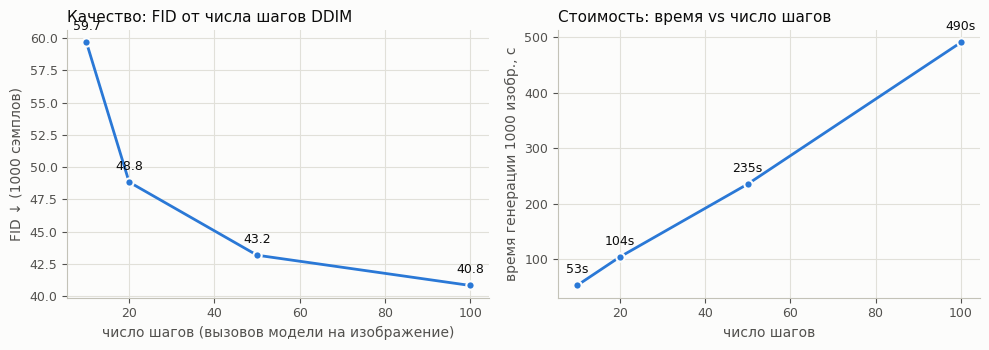

In [11]:
# --- графики: FID и время от числа шагов ----------------------------------------------
INK, SEC, MUT, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES, SURF = "#2a78d6", "#fcfcfb"

def style_ax(ax):
    ax.set_facecolor(SURF)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(BASE)
    ax.tick_params(colors=SEC, labelsize=9)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), facecolor=SURF)
steps = df.index.to_numpy(dtype=float)

ax1.plot(steps, df["fid"], color=SERIES, lw=2, marker="o", ms=6, mfc=SERIES, mec=SURF, mew=1.5)
for x, y in zip(steps, df["fid"]):
    ax1.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9, color=INK)
ax1.set_xlabel("число шагов (вызовов модели на изображение)", color=SEC)
ax1.set_ylabel("FID ↓ (1000 сэмплов)", color=SEC)
ax1.set_title("Качество: FID от числа шагов DDIM", color=INK, fontsize=11, loc="left")

ax2.plot(steps, df["time_s"], color=SERIES, lw=2, marker="o", ms=6, mfc=SERIES, mec=SURF, mew=1.5)
for x, y in zip(steps, df["time_s"]):
    ax2.annotate(f"{y:.0f}s", (x, y), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9, color=INK)
ax2.set_xlabel("число шагов", color=SEC)
ax2.set_ylabel("время генерации 1000 изобр., с", color=SEC)
ax2.set_title("Стоимость: время vs число шагов", color=INK, fontsize=11, loc="left")

for ax in (ax1, ax2):
    style_ax(ax)
plt.tight_layout(); plt.show()

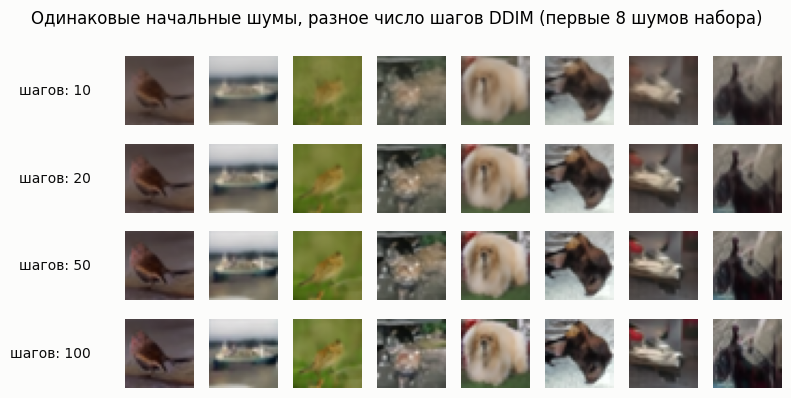

In [12]:
# --- визуальное сравнение: один и тот же шум при разном числе шагов --------------------
n_show = 8
rows = [torch.load(f"data/generated/ddim_{n}steps.pt") for n in STEPS_GRID]
fig, axes = plt.subplots(len(STEPS_GRID), n_show, figsize=(n_show * 1.0, len(STEPS_GRID) * 1.0),
                         facecolor=SURF)
for r, (n, row) in enumerate(zip(STEPS_GRID, rows)):
    for c in range(n_show):
        ax = axes[r, c]
        ax.imshow((row[c].permute(1, 2, 0).numpy()).astype(np.float32) / 255)
        ax.set_axis_off()
        if c == 0:
            ax.text(-0.5, 0.5, f"шагов: {n}", transform=ax.transAxes,
                    ha="right", va="center", fontsize=10, color=INK)
fig.suptitle("Одинаковые начальные шумы, разное число шагов DDIM (первые 8 шумов набора)", y=0.99)
plt.tight_layout(); plt.show()